# Bike Sharing Prediction Using Regression Models and Gradient Descent

**Student Name:** Vedant Jagdish Patil  
**PRN:** 202401040209  
**Batch:** A2  
**Roll No.:** 50    
**Dataset:**  Bike Sharing Dataset    
**Real-world application:** Predicting the number of bicycles rented per hour.

---

## 1. Aim

1. Develop regression models for the real-world application of bike-sharing demand prediction and evaluate them using appropriate regression metrics.
2. Implement and analyze Batch Gradient Descent optimization for Linear Regression and compare its performance with the analytical Linear Regression solution.

## 2. Problem statement and application

Bike-sharing systems require accurate demand forecasting to determine how many bicycles customers may rent at different times. These predictions help operators maintain sufficient bike availability, manage resources, and improve service efficiency.

In this notebook, we use machine learning techniques to predict hourly bike rental demand (cnt) based on different factors, including weather conditions, seasonal patterns, dates, and time-related features.

## 3. Dataset description

The UCI Bike Sharing Dataset provides hourly and daily bicycle rental information. In this project, we use the hour.csv file, which consists of 17,379 hourly records.

The dataset includes several features that help understand rental patterns, such as season, year, month, hour, holidays, weekdays, and weather conditions. It also contains temperature, humidity, and wind speed measurements.

The main objective is to predict the total number of bicycle rentals (cnt) using these available features.

Data preprocessing: To avoid data leakage, the casual and registered columns are removed because their combined values directly represent the target variable cnt. The instant and dteday columns are also excluded from model training, while the date information is temporarily used to maintain the correct chronological order of records.

## 4. Regression models

This experiment compares:
1. Linear Regression
2. Ridge Regression
3. Lasso Regression
4. Random Forest Regressor

It then implements Batch Gradient Descent manually for Linear Regression.

## 5. Evaluation metrics

- **MAE:** Average absolute prediction error; lower is better.
- **MSE:** Average squared prediction error; lower is better.
- **RMSE:** Square root of MSE, expressed in the target's units; lower is better.
- **R² score:** Proportion of target variance explained by the model; closer to 1 is generally better.

The target `cnt` is the number of rented bicycles per hour, so MAE and RMSE are interpreted in bicycles per hour.


## 6. Import libraries

In [47]:
import io
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


## 7. Download and load the UCI Bike Sharing dataset

The dataset is downloaded directly from the UCI Machine Learning Repository. No manual upload is required in Google Colab.

In [48]:
dataset_url = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"

response = requests.get(dataset_url, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    hour_file = next(name for name in z.namelist() if name.endswith("hour.csv"))
    with z.open(hour_file) as f:
        df = pd.read_csv(f)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## 8. Understand and explore the data

In [49]:
print("Dataset information:")
df.info()

print("\nMissing values per column:")
display(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe().T)

print("\nDate range:", df["dteday"].min(), "to", df["dteday"].max())
print("Total hourly records:", len(df))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB

Missing values per column:


,0
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0



Statistical summary:


,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.000000,5017.029500,1.00,4345.5000,8690.0000,13034.5000,17379.0000
season,17379.0,2.501640,1.106918,1.00,2.0000,3.0000,3.0000,4.0000
yr,17379.0,0.502561,0.500008,0.00,0.0000,1.0000,1.0000,1.0000
mnth,17379.0,6.537775,3.438776,1.00,4.0000,7.0000,10.0000,12.0000
hr,17379.0,11.546752,6.914405,0.00,6.0000,12.0000,18.0000,23.0000
holiday,17379.0,0.028770,0.167165,0.00,0.0000,0.0000,0.0000,1.0000
weekday,17379.0,3.003683,2.005771,0.00,1.0000,3.0000,5.0000,6.0000
workingday,17379.0,0.682721,0.465431,0.00,0.0000,1.0000,1.0000,1.0000
weathersit,17379.0,1.425283,0.639357,1.00,1.0000,1.0000,2.0000,4.0000
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000



Date range: 2011-01-01 to 2012-12-31
Total hourly records: 17379


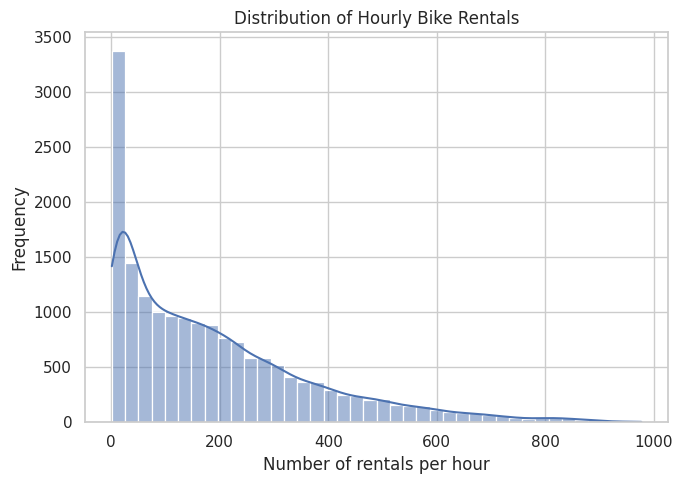

In [50]:
plt.figure(figsize=(7, 5))
sns.histplot(df["cnt"], bins=40, kde=True)
plt.title("Distribution of Hourly Bike Rentals")
plt.xlabel("Number of rentals per hour")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

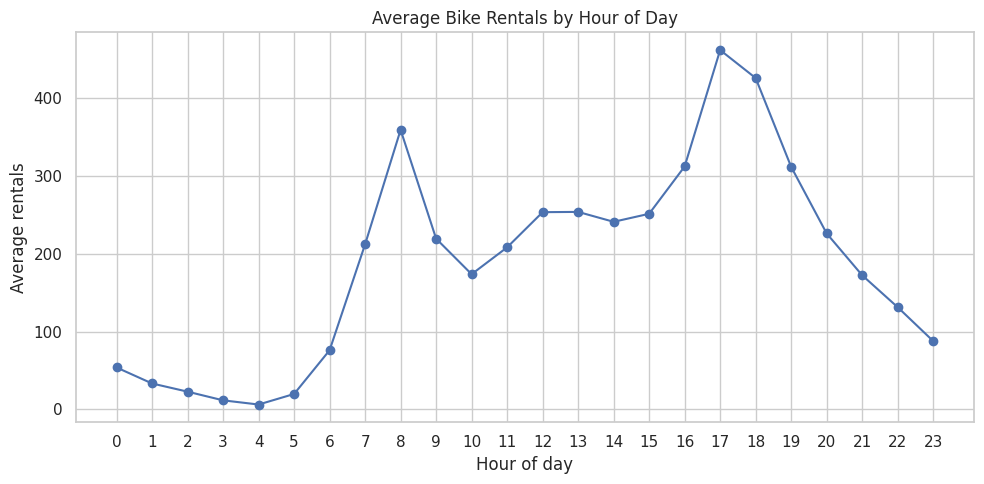

In [51]:
hourly_average = df.groupby("hr")["cnt"].mean()

plt.figure(figsize=(10, 5))
hourly_average.plot(marker="o")
plt.title("Average Bike Rentals by Hour of Day")
plt.xlabel("Hour of day")
plt.ylabel("Average rentals")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

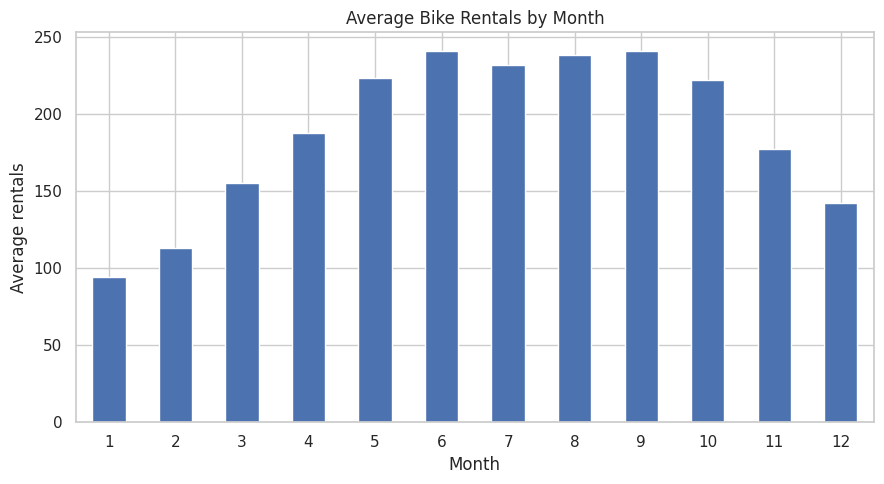

In [52]:
monthly_average = df.groupby("mnth")["cnt"].mean()

plt.figure(figsize=(9, 5))
monthly_average.plot(kind="bar")
plt.title("Average Bike Rentals by Month")
plt.xlabel("Month")
plt.ylabel("Average rentals")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 9. Prepare features and target

The target variable is `cnt`. We exclude:
- `casual` and `registered`, because they directly add up to the target and would cause target leakage.
- `instant`, because it is only a row identifier.
- `dteday`, because the date is used to order the observations, not as a raw text feature.

The data is sorted by date and split chronologically: the earliest 80% is used for training and the latest 20% for testing. This is a more realistic evaluation for forecasting future demand than randomly mixing past and future records.

In [53]:
# Sort records by date and hour
df["dteday"] = pd.to_datetime(df["dteday"])
df = df.sort_values(["dteday", "hr"]).reset_index(drop=True)

target = "cnt"
excluded_columns = ["cnt", "casual", "registered", "instant", "dteday"]

X = df.drop(columns=excluded_columns)
y = df[target]

# Chronological 80:20 split
split_index = int(len(df) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()
y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("Input features:", list(X.columns))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training date range:", df["dteday"].iloc[0], "to", df["dteday"].iloc[split_index - 1])
print("Testing date range:", df["dteday"].iloc[split_index], "to", df["dteday"].iloc[-1])

Input features: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']
Training records: 13903
Testing records: 3476
Training date range: 2011-01-01 00:00:00 to 2012-08-07 00:00:00
Testing date range: 2012-08-07 00:00:00 to 2012-12-31 00:00:00


## 10. Build and train regression models

StandardScaler is included in pipelines for Linear, Ridge and Lasso Regression. It is fitted only on training data. Random Forest does not require feature scaling.

In [54]:
models = {
    "Linear Regression": make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),
    "Ridge Regression": make_pipeline(
        StandardScaler(),
        Ridge(alpha=1.0)
    ),
    "Lasso Regression": make_pipeline(
        StandardScaler(),
        Lasso(alpha=0.01, max_iter=20000)
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        max_depth=18,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully.")

Linear Regression trained successfully.
Ridge Regression trained successfully.
Lasso Regression trained successfully.
Random Forest trained successfully.


## 11. Make predictions and evaluate the models

In [55]:
predictions = {}
results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results).set_index("Model")
print("Regression model comparison:")
display(results_df.round(4))

Regression model comparison:


,MAE,MSE,RMSE,R2 Score
Model,,,,
Linear Regression,138.2918,33590.7693,183.2778,0.3090
Ridge Regression,138.2918,33591.2857,183.2793,0.3090
Lasso Regression,138.2861,33593.4449,183.2851,0.3090
Random Forest,45.1033,4889.6956,69.9264,0.8994


## 12. Visualize model performance

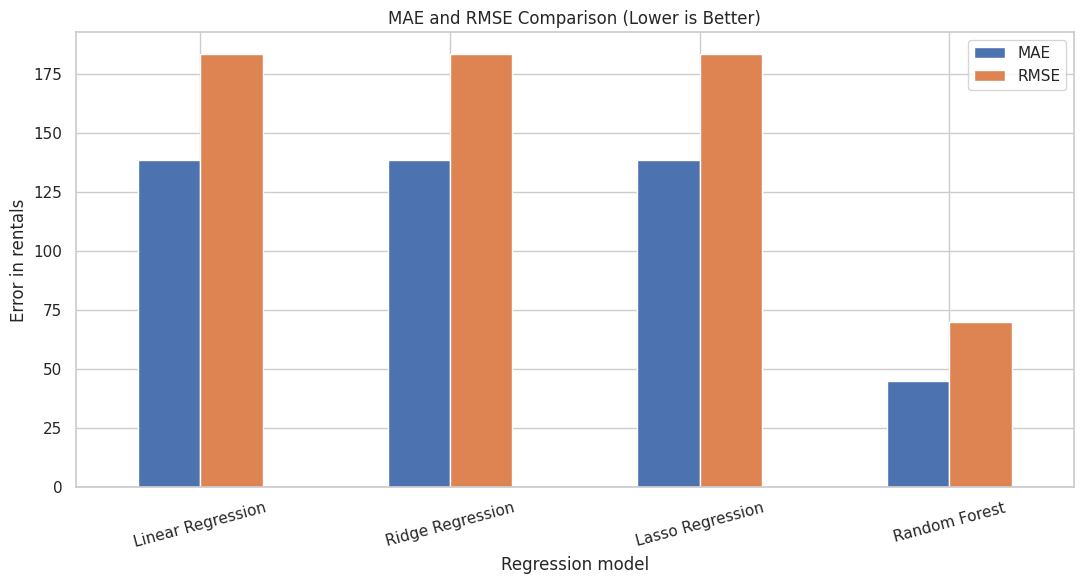

In [56]:
results_df[["MAE", "RMSE"]].plot(
    kind="bar", figsize=(11, 6)
)
plt.title("MAE and RMSE Comparison (Lower is Better)")
plt.xlabel("Regression model")
plt.ylabel("Error in rentals")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

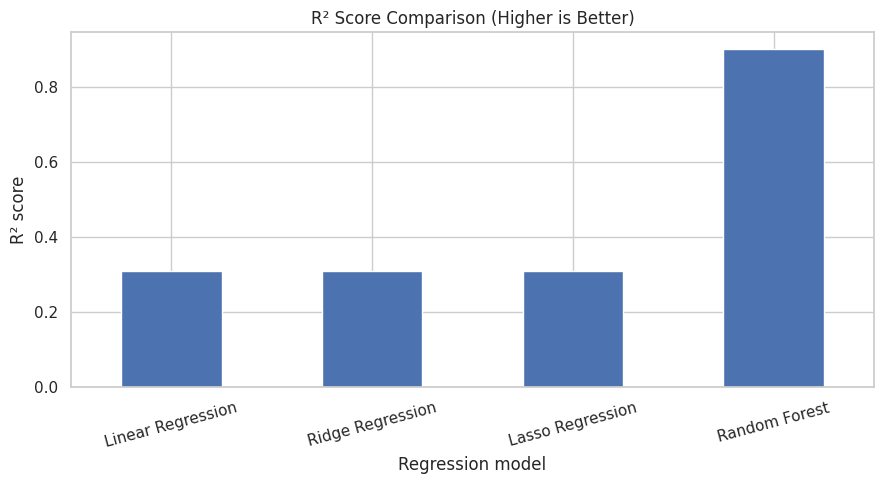

In [57]:
results_df[["R2 Score"]].plot(
    kind="bar", figsize=(9, 5), legend=False
)
plt.title("R² Score Comparison (Higher is Better)")
plt.xlabel("Regression model")
plt.ylabel("R² score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 13. Actual vs predicted values for the best model

The model with the lowest test RMSE is selected for this visualization. Points closer to the diagonal reference line indicate more accurate predictions.

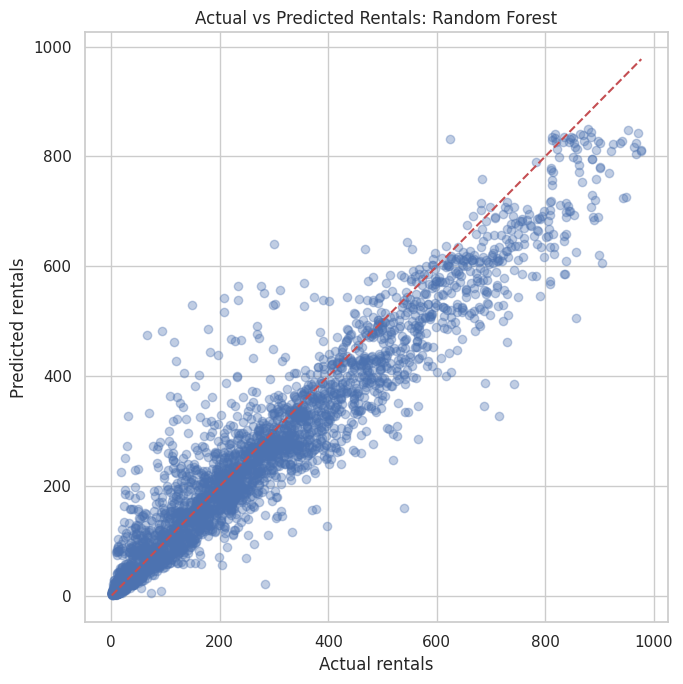

Best model by test RMSE: Random Forest


In [58]:
best_model_name = results_df["RMSE"].idxmin()
best_predictions = predictions[best_model_name]

plt.figure(figsize=(7, 7))
plt.scatter(y_test, best_predictions, alpha=0.35)
line_min = min(y_test.min(), best_predictions.min())
line_max = max(y_test.max(), best_predictions.max())
plt.plot([line_min, line_max], [line_min, line_max], "r--")
plt.title(f"Actual vs Predicted Rentals: {best_model_name}")
plt.xlabel("Actual rentals")
plt.ylabel("Predicted rentals")
plt.tight_layout()
plt.show()

print("Best model by test RMSE:", best_model_name)

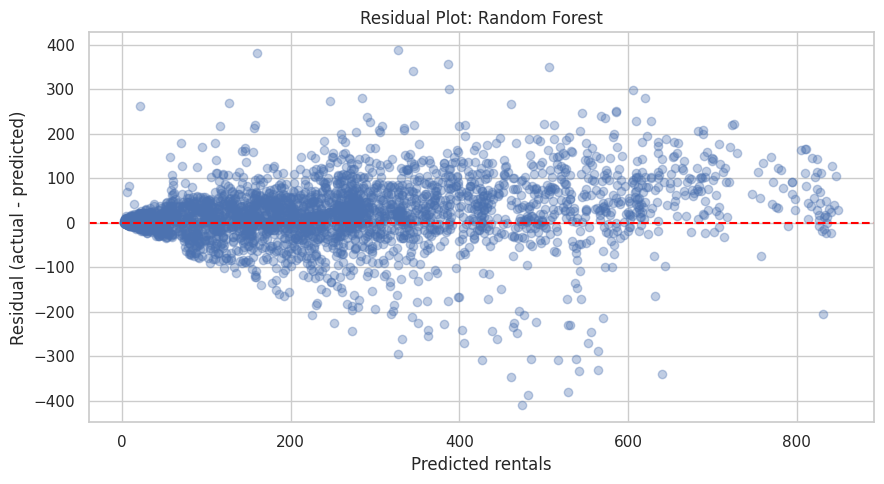

In [59]:
residuals = y_test.to_numpy() - best_predictions

plt.figure(figsize=(9, 5))
plt.scatter(best_predictions, residuals, alpha=0.35)
plt.axhline(0, color="red", linestyle="--")
plt.title(f"Residual Plot: {best_model_name}")
plt.xlabel("Predicted rentals")
plt.ylabel("Residual (actual - predicted)")
plt.tight_layout()
plt.show()

## 14. Feature importance (Random Forest)

Random Forest can estimate the relative importance of input features. These values describe how much the features contributed to reducing impurity across the trees; they do not prove causation.

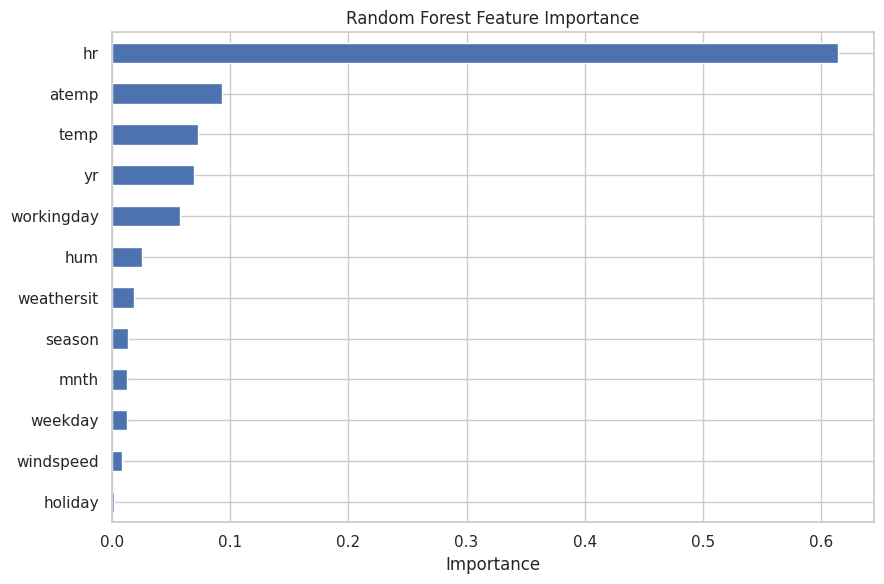

In [60]:
rf_model = models["Random Forest"]
importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

plt.figure(figsize=(9, 6))
importance.plot(kind="barh")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

# Part B: Manual Gradient Descent for Linear Regression

## 15. What is Gradient Descent?

Gradient Descent is an optimization method that repeatedly updates model parameters in the direction that reduces the cost function.

For linear regression, the prediction is a weighted sum of the input features plus an intercept. We use Mean Squared Error as the cost function.

In this section, features and target are standardized using training data only. This improves numerical stability and makes a single learning rate more practical. Predictions are converted back to the original bicycle-count scale before evaluation.

## 16. Prepare scaled data for manual Gradient Descent

In [61]:
# Fit scalers using training data only
gd_x_scaler = StandardScaler()
X_train_scaled = gd_x_scaler.fit_transform(X_train)
X_test_scaled = gd_x_scaler.transform(X_test)

gd_y_scaler = StandardScaler()
y_train_scaled = gd_y_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()

# Add a column of ones for the intercept (bias)
X_train_gd = np.c_[np.ones(X_train_scaled.shape[0]), X_train_scaled]
X_test_gd = np.c_[np.ones(X_test_scaled.shape[0]), X_test_scaled]

print("Scaled training matrix shape:", X_train_gd.shape)
print("Scaled testing matrix shape:", X_test_gd.shape)

Scaled training matrix shape: (13903, 13)
Scaled testing matrix shape: (3476, 13)


## 17. Implement Batch Gradient Descent manually

At each iteration, the algorithm calculates predictions, computes the gradient of the mean squared error, and updates all weights together. The first parameter represents the intercept.

In [62]:
def batch_gradient_descent(X, y, learning_rate=0.03, iterations=5000):
    n_samples, n_features = X.shape
    weights = np.zeros(n_features)
    cost_history = []

    for iteration in range(iterations):
        predictions = X @ weights
        errors = predictions - y

        # Gradient of mean squared error
        gradients = (2 / n_samples) * (X.T @ errors)

        # Update parameters
        weights = weights - learning_rate * gradients

        # Store cost after parameter update
        new_predictions = X @ weights
        cost = np.mean((new_predictions - y) ** 2)
        cost_history.append(cost)

    return weights, cost_history


gd_weights, cost_history = batch_gradient_descent(
    X_train_gd,
    y_train_scaled,
    learning_rate=0.03,
    iterations=5000
)

print("Gradient Descent completed.")
print("Learned intercept (scaled target):", gd_weights[0])
print("Final training MSE (scaled target):", cost_history[-1])

Gradient Descent completed.
Learned intercept (scaled target): -1.0677593696172677e-16
Final training MSE (scaled target): 0.6067487054829495


## 18. Plot cost reduction over iterations

A decreasing cost curve indicates that Gradient Descent is reducing the training error. If the curve is still decreasing sharply at the end, more iterations may be needed.

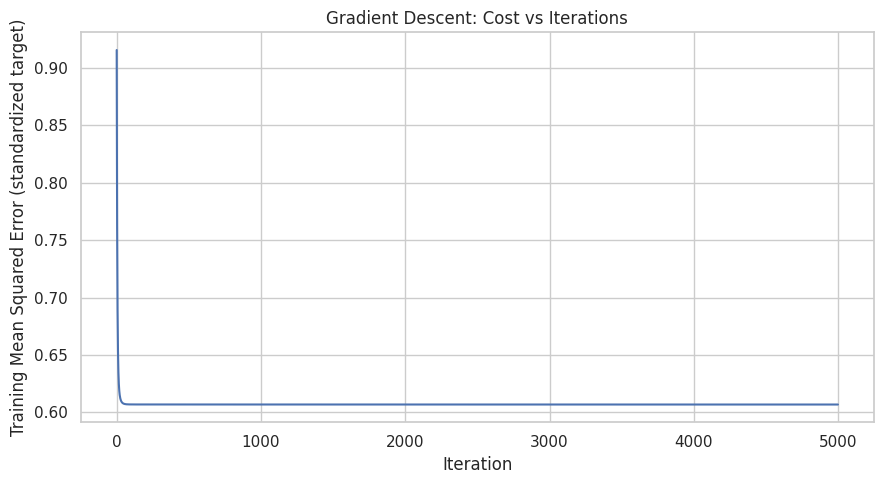

Initial cost: 0.915627
Final cost: 0.606749


In [63]:
plt.figure(figsize=(9, 5))
plt.plot(cost_history)
plt.title("Gradient Descent: Cost vs Iterations")
plt.xlabel("Iteration")
plt.ylabel("Training Mean Squared Error (standardized target)")
plt.tight_layout()
plt.show()

print("Initial cost:", round(cost_history[0], 6))
print("Final cost:", round(cost_history[-1], 6))

## 19. Evaluate manual Gradient Descent

In [64]:
# Predict in standardized target units, then reverse target scaling
gd_test_scaled_predictions = X_test_gd @ gd_weights
gd_predictions = gd_y_scaler.inverse_transform(
    gd_test_scaled_predictions.reshape(-1, 1)
).ravel()

gd_mae = mean_absolute_error(y_test, gd_predictions)
gd_mse = mean_squared_error(y_test, gd_predictions)
gd_rmse = np.sqrt(gd_mse)
gd_r2 = r2_score(y_test, gd_predictions)

gd_results = pd.DataFrame([{
    "Model": "Manual Gradient Descent",
    "MAE": gd_mae,
    "MSE": gd_mse,
    "RMSE": gd_rmse,
    "R2 Score": gd_r2
}]).set_index("Model")

display(gd_results.round(4))

,MAE,MSE,RMSE,R2 Score
Model,,,,
Manual Gradient Descent,138.301,33591.8947,183.2809,0.309


## 20. Compare Gradient Descent with Scikit-learn Linear Regression

Both methods optimize the same linear regression objective on the same standardized training data. Scikit-learn's LinearRegression uses a least-squares solver, while the manual implementation approaches the solution iteratively.

In [65]:
# Fit sklearn Linear Regression on the same scaled X and scaled y
sklearn_lr = LinearRegression()
sklearn_lr.fit(X_train_gd[:, 1:], y_train_scaled)

sklearn_lr_scaled_predictions = sklearn_lr.predict(X_test_gd[:, 1:])
sklearn_lr_predictions = gd_y_scaler.inverse_transform(
    sklearn_lr_scaled_predictions.reshape(-1, 1)
).ravel()

comparison_gd = pd.DataFrame([
    {
        "Method": "Manual Gradient Descent",
        "MAE": mean_absolute_error(y_test, gd_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, gd_predictions)),
        "R2 Score": r2_score(y_test, gd_predictions)
    },
    {
        "Method": "Scikit-learn Linear Regression",
        "MAE": mean_absolute_error(y_test, sklearn_lr_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, sklearn_lr_predictions)),
        "R2 Score": r2_score(y_test, sklearn_lr_predictions)
    }
]).set_index("Method")

display(comparison_gd.round(4))

,MAE,RMSE,R2 Score
Method,,,
Manual Gradient Descent,138.3010,183.2809,0.309
Scikit-learn Linear Regression,138.2918,183.2778,0.309


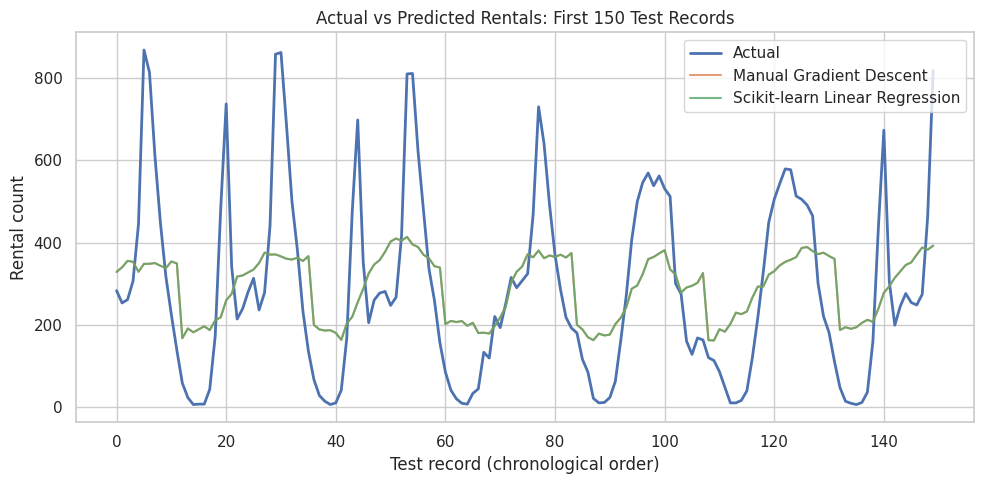

In [66]:
plt.figure(figsize=(10, 5))
plt.plot(y_test.to_numpy()[:150], label="Actual", linewidth=2)
plt.plot(gd_predictions[:150], label="Manual Gradient Descent", alpha=0.8)
plt.plot(sklearn_lr_predictions[:150], label="Scikit-learn Linear Regression", alpha=0.8)
plt.title("Actual vs Predicted Rentals: First 150 Test Records")
plt.xlabel("Test record (chronological order)")
plt.ylabel("Rental count")
plt.legend()
plt.tight_layout()
plt.show()

## 21. Analyze the effect of learning rate

A learning rate controls the size of each parameter update. A very small rate can make convergence slow; a rate that is too large can cause unstable updates or divergence. The following experiment compares a few learning rates using the same scaled training data.

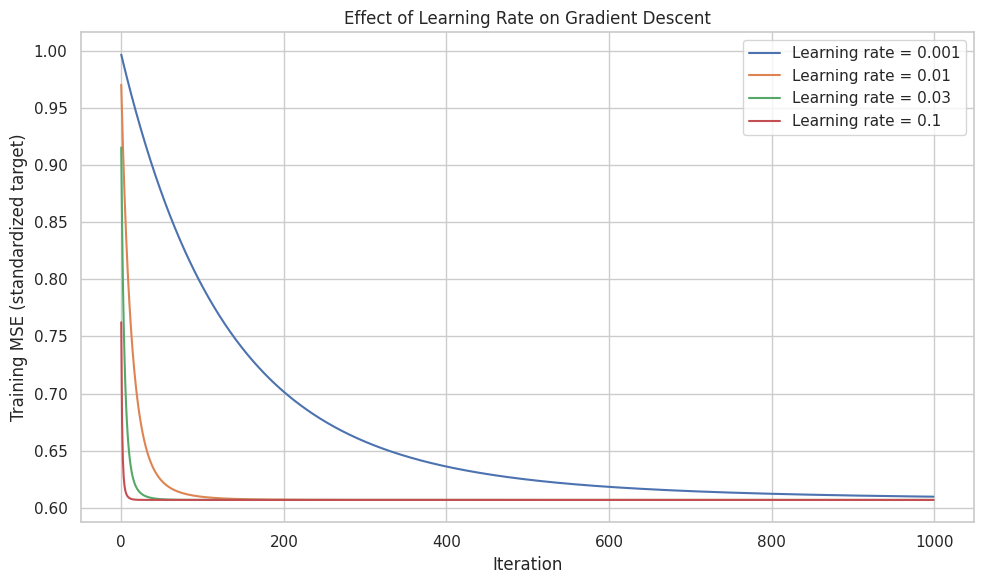

Learning rate 0.001: initial cost=0.99701, final cost=0.60964
Learning rate 0.01: initial cost=0.97063, final cost=0.60679
Learning rate 0.03: initial cost=0.91563, final cost=0.60677
Learning rate 0.1: initial cost=0.76248, final cost=0.60675


In [67]:
learning_rates = [0.001, 0.01, 0.03, 0.1]
lr_histories = {}

for lr in learning_rates:
    _, history = batch_gradient_descent(
        X_train_gd,
        y_train_scaled,
        learning_rate=lr,
        iterations=1000
    )
    lr_histories[lr] = history

plt.figure(figsize=(10, 6))
for lr, history in lr_histories.items():
    plt.plot(history, label=f"Learning rate = {lr}")

plt.title("Effect of Learning Rate on Gradient Descent")
plt.xlabel("Iteration")
plt.ylabel("Training MSE (standardized target)")
plt.legend()
plt.tight_layout()
plt.show()

for lr, history in lr_histories.items():
    print(f"Learning rate {lr}: initial cost={history[0]:.5f}, final cost={history[-1]:.5f}")

## 22. Automatically identify the best regression model

In [68]:
print("BEST MODEL BY EACH METRIC")
print("-" * 50)

print("Lowest MAE:", results_df["MAE"].idxmin(),
      f"({results_df['MAE'].min():.3f})")
print("Lowest MSE:", results_df["MSE"].idxmin(),
      f"({results_df['MSE'].min():.3f})")
print("Lowest RMSE:", results_df["RMSE"].idxmin(),
      f"({results_df['RMSE'].min():.3f})")
print("Highest R2:", results_df["R2 Score"].idxmax(),
      f"({results_df['R2 Score'].max():.3f})")

print("\nAll regression results:")
display(results_df.round(4))

print("\nGradient Descent comparison:")
display(comparison_gd.round(4))

BEST MODEL BY EACH METRIC
--------------------------------------------------
Lowest MAE: Random Forest (45.103)
Lowest MSE: Random Forest (4889.696)
Lowest RMSE: Random Forest (69.926)
Highest R2: Random Forest (0.899)

All regression results:


,MAE,MSE,RMSE,R2 Score
Model,,,,
Linear Regression,138.2918,33590.7693,183.2778,0.3090
Ridge Regression,138.2918,33591.2857,183.2793,0.3090
Lasso Regression,138.2861,33593.4449,183.2851,0.3090
Random Forest,45.1033,4889.6956,69.9264,0.8994



Gradient Descent comparison:


,MAE,RMSE,R2 Score
Method,,,
Manual Gradient Descent,138.3010,183.2809,0.309
Scikit-learn Linear Regression,138.2918,183.2778,0.309


## 23. Comparative analysis

### Regression model comparison

- **Linear Regression:** A simple and interpretable baseline. It models a linear relationship between the selected input features and rental demand.
- **Ridge Regression:** Adds L2 regularization, which can reduce the effect of large coefficients and help when features are correlated.
- **Lasso Regression:** Adds L1 regularization and can shrink some coefficients to zero, which may help with feature selection.
- **Random Forest Regressor:** Combines many decision trees and can capture nonlinear relationships and feature interactions. It is less directly interpretable than linear models.

### Gradient Descent analysis

- Gradient Descent starts with initial parameter values and updates them iteratively.
- The cost-versus-iteration graph shows whether the optimization is converging.
- The learning rate controls the update size.
- Manual Gradient Descent should approach the Scikit-learn Linear Regression solution when it converges sufficiently, because both are optimizing the same least-squares objective on the same transformed training data.
- Small differences can occur due to the finite number of iterations and numerical precision.

### Suitability

For hourly bike rental demand, nonlinear patterns may exist because demand changes with hour, season and weather. Linear models are useful baselines and are easier to interpret. Random Forest may capture more complex patterns, but its measured test performance should decide whether it is preferable for this experiment.

Use the actual metric table and plots above to support the final choice. Do not assume that one model is best before examining the test results.

## 24. Conclusion

In [69]:
best_rmse_name = results_df["RMSE"].idxmin()
best_r2_name = results_df["R2 Score"].idxmax()

print("CONCLUSION SUMMARY")
print("-" * 55)
print(f"Best model by RMSE: {best_rmse_name}")
print(f"Best model by R2 score: {best_r2_name}")
print(f"Manual Gradient Descent test RMSE: {gd_rmse:.3f}")
print(f"Scikit-learn Linear Regression test RMSE: "
      f"{np.sqrt(mean_squared_error(y_test, sklearn_lr_predictions)):.3f}")
print("\nUse the metric table and visualizations to write the final comparison.")

CONCLUSION SUMMARY
-------------------------------------------------------
Best model by RMSE: Random Forest
Best model by R2 score: Random Forest
Manual Gradient Descent test RMSE: 183.281
Scikit-learn Linear Regression test RMSE: 183.278

Use the metric table and visualizations to write the final comparison.


### Conclusion

In this practical, different regression models were implemented to predict hourly bike rental demand using the UCI Bike Sharing Dataset. Linear Regression, Ridge Regression, Lasso Regression, and Random Forest Regression were trained and evaluated using various performance metrics. Batch Gradient Descent was also implemented manually to understand model optimization and convergence. This practical provided hands-on knowledge of regression techniques and their application in predicting real-world demand using machine learning.